# TruthLens — Video Deepfake Detection (EfficientNet-B0)

**Dataset:** FaceForensics++ subset (200 real + 200 fake) · **Model:** EfficientNet-B0 (ImageNet pretrained) · **Task:** binary (0 = REAL, 1 = FAKE)

**Pipeline:** video → video-level split → 12 frames/video → face detect → crop + align → 224×224 → augmentation → EfficientNet-B0 → frame probability → mean aggregation → video-level REAL/FAKE + confidence

**Before you run (Kaggle settings):**
1. Add the dataset `hungle3401/faceforensics` to the notebook (Add Input).
2. Accelerator: **GPU** (T4 / P100).
3. Internet: **ON** (needed once to download ImageNet weights + `facenet-pytorch` for MTCNN face detection; the notebook falls back to OpenCV Haar if MTCNN is unavailable).
   

In [1]:
import os, sys, json, math, random, time, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device:", device, "|", torch.cuda.get_device_name(0) if use_amp else "CPU only (enable GPU in Kaggle settings!)")
print("torch", torch.__version__)

# MTCNN (face detection + landmarks for alignment). Falls back to OpenCV Haar if unavailable.
try:
    from facenet_pytorch import MTCNN
    HAS_MTCNN = True
except Exception:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "facenet-pytorch", "--no-deps"],
                       check=True, timeout=600)
        from facenet_pytorch import MTCNN
        HAS_MTCNN = True
    except Exception as e:
        print("MTCNN unavailable -> using OpenCV Haar fallback (no landmark alignment):", e)
        HAS_MTCNN = False
print("MTCNN available:", HAS_MTCNN)

Device: cuda | Tesla T4
torch 2.11.0+cu128
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 22.2 MB/s eta 0:00:00
MTCNN available: True


In [2]:
CFG = dict(
    real_dir = "/kaggle/input/datasets/hungle3401/faceforensics/FF++/real",
    fake_dir = "/kaggle/input/datasets/hungle3401/faceforensics/FF++/fake",
    n_per_class = 200,          # balanced subset
    frames_per_video = 12,
    img_size = 224,
    face_margin = 0.20,         # margin added on each side of the face box
    detect_max_side = 960,      # downscale big frames before detection (speed)
    train_frac = 0.70, val_frac = 0.15, test_frac = 0.15,
    batch_size = 32, epochs = 5, patience = 3,
    lr = 1e-4, weight_decay = 1e-4,
    num_workers = 2,
    seed = SEED,
)
WORK = Path("/kaggle/working")
FACES_DIR = WORK / "faces"
OUT_DIR   = WORK / "outputs"
FACES_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

## 1. Collect videos and split at VIDEO level (before any frame extraction)

In [3]:
VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv", ".webm"}

def resolve_dir(path, name):
    # If the given path is wrong, try to locate a folder called `name` under /kaggle/input.
    if Path(path).exists():
        return Path(path)
    print(f"[warn] {path} not found, searching /kaggle/input for a '{name}' folder ...")
    hits = [p for p in Path("/kaggle/input").rglob(name) if p.is_dir()]
    if not hits:
        raise FileNotFoundError(f"Could not find a '{name}' directory. Check that the dataset is attached.")
    print("   using:", hits[0]); return hits[0]

def list_videos(d):
    return sorted(p for p in Path(d).rglob("*") if p.suffix.lower() in VIDEO_EXTS)

real_vids = list_videos(resolve_dir(CFG["real_dir"], "real"))
fake_vids = list_videos(resolve_dir(CFG["fake_dir"], "fake"))
print(f"Found: real={len(real_vids)}  fake={len(fake_vids)}")

rng = random.Random(CFG["seed"])
n = CFG["n_per_class"]
real_sel = rng.sample(real_vids, min(n, len(real_vids)))
fake_sel = rng.sample(fake_vids, min(n, len(fake_vids)))
k = min(len(real_sel), len(fake_sel))          # keep the subset balanced
real_sel, fake_sel = real_sel[:k], fake_sel[:k]

df = pd.DataFrame({"path": [str(p) for p in real_sel + fake_sel],
                   "label": [0]*len(real_sel) + [1]*len(fake_sel)})
df["video_id"] = [f"v{i:04d}" for i in range(len(df))]

# Stratified 70 / 15 / 15 split, seed 42
train_df, temp_df = train_test_split(df, test_size=CFG["val_frac"] + CFG["test_frac"],
                                     stratify=df["label"], random_state=CFG["seed"])
val_df, test_df = train_test_split(temp_df, test_size=CFG["test_frac"] / (CFG["val_frac"] + CFG["test_frac"]),
                                  stratify=temp_df["label"], random_state=CFG["seed"])
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
train_df["split"], val_df["split"], test_df["split"] = "train", "val", "test"
split_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
split_df.to_csv(OUT_DIR / "video_splits.csv", index=False)

print(split_df.groupby(["split", "label"]).size().unstack(fill_value=0).rename(columns={0: "real", 1: "fake"}))
# sanity: no video appears in two splits
assert split_df["video_id"].is_unique and split_df["path"].is_unique

Found: real=200  fake=200
label  real  fake
split            
test     30    30
train   140   140
val      30    30


## 2. Frame sampling → face detection → crop + align → 224×224

In [4]:
if HAS_MTCNN:
    mtcnn = MTCNN(keep_all=True, device=device, thresholds=[0.6, 0.7, 0.7], post_process=False)
    haar = None
else:
    mtcnn = None
    haar = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def sample_frames(video_path, n_frames):
    # n_frames evenly spaced RGB frames (skips the very first/last frame).
    cap = cv2.VideoCapture(str(video_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    if total > 0:
        idxs = np.linspace(0, total - 1, n_frames + 2)[1:-1].astype(int) if total > n_frames + 2 \
               else np.arange(total)
        for i in np.unique(idxs):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
            ok, f = cap.read()
            if ok and f is not None:
                frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    else:  # unknown frame count: read sequentially and subsample
        buf = []
        while True:
            ok, f = cap.read()
            if not ok: break
            buf.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        if buf:
            frames = [buf[i] for i in np.unique(np.linspace(0, len(buf) - 1, n_frames).astype(int))]
    cap.release()
    return frames

def detect_largest_face(rgb):
    # Returns (box[x1,y1,x2,y2], landmarks[5,2] or None) in original-frame coordinates, or (None, None).
    h, w = rgb.shape[:2]
    scale = min(1.0, CFG["detect_max_side"] / max(h, w))
    small = cv2.resize(rgb, (int(w * scale), int(h * scale))) if scale < 1 else rgb
    if mtcnn is not None:
        boxes, probs, pts = mtcnn.detect(small, landmarks=True)
        if boxes is None or len(boxes) == 0:
            return None, None
        areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
        i = int(np.argmax(areas))
        return boxes[i] / scale, (pts[i] / scale if pts is not None else None)
    gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
    faces = haar.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
    if len(faces) == 0:
        return None, None
    x, y, fw, fh = max(faces, key=lambda b: b[2] * b[3])
    return np.array([x, y, x + fw, y + fh], dtype=float) / scale, None

def crop_square(img, cx, cy, side):
    h, w = img.shape[:2]
    half = side // 2
    x1, y1 = cx - half, cy - half
    x2, y2 = x1 + side, y1 + side
    pad = max(0, -x1, -y1, x2 - w, y2 - h)
    if pad > 0:
        img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
        x1 += pad; x2 += pad; y1 += pad; y2 += pad
    return img[y1:y2, x1:x2]

def align_and_crop(rgb, box, pts):
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    if pts is not None:  # rotate so the eye line is horizontal
        (lx, ly), (rx, ry) = pts[0], pts[1]
        angle = math.degrees(math.atan2(ry - ly, rx - lx))
        M = cv2.getRotationMatrix2D((float(cx), float(cy)), angle, 1.0)
        rgb = cv2.warpAffine(rgb, M, (rgb.shape[1], rgb.shape[0]), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT)
    side = int(max(x2 - x1, y2 - y1) * (1 + 2 * CFG["face_margin"]))
    crop = crop_square(rgb, int(cx), int(cy), max(side, 16))
    return cv2.resize(crop, (CFG["img_size"], CFG["img_size"]), interpolation=cv2.INTER_AREA)

def center_crop(rgb):
    h, w = rgb.shape[:2]; s = min(h, w)
    return cv2.resize(rgb[(h - s)//2:(h - s)//2 + s, (w - s)//2:(w - s)//2 + s],
                      (CFG["img_size"], CFG["img_size"]), interpolation=cv2.INTER_AREA)

def extract_faces(video_path, n_frames=None):
    # Shared by training preprocessing AND inference so both see identical inputs.
    # Returns (list of 224x224 RGB uint8 faces, n_frames_read, n_faces_detected)
    n_frames = n_frames or CFG["frames_per_video"]
    frames = sample_frames(video_path, n_frames)
    faces = []
    for rgb in frames:
        box, pts = detect_largest_face(rgb)
        if box is not None:
            faces.append(align_and_crop(rgb, box, pts))
    n_det = len(faces)
    if n_det == 0 and frames:                      # no face anywhere -> keep the video via center crops
        faces = [center_crop(f) for f in frames]
    return faces, len(frames), n_det

In [5]:
MANIFEST = OUT_DIR / "frame_manifest.csv"
VSTATS   = OUT_DIR / "video_extraction_stats.csv"

if MANIFEST.exists() and VSTATS.exists():
    frame_df = pd.read_csv(MANIFEST); vstats = pd.read_csv(VSTATS)
    print("Loaded cached manifest:", len(frame_df), "frames")
else:
    rows, stats = [], []
    t0 = time.time()
    for r in tqdm(split_df.itertuples(index=False), total=len(split_df), desc="Extracting faces"):
        faces, n_read, n_det = extract_faces(r.path)
        stats.append(dict(video_id=r.video_id, split=r.split, label=r.label,
                          frames_read=n_read, faces_detected=n_det, used_fallback=int(n_det == 0)))
        out_d = FACES_DIR / r.split / ("fake" if r.label == 1 else "real")
        out_d.mkdir(parents=True, exist_ok=True)
        for j, f in enumerate(faces):
            fp = out_d / f"{r.video_id}_{j:02d}.jpg"
            cv2.imwrite(str(fp), cv2.cvtColor(f, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])
            rows.append(dict(split=r.split, video_id=r.video_id, label=r.label, frame_idx=j, path=str(fp)))
    frame_df, vstats = pd.DataFrame(rows), pd.DataFrame(stats)
    frame_df.to_csv(MANIFEST, index=False); vstats.to_csv(VSTATS, index=False)
    print(f"Done in {(time.time() - t0)/60:.1f} min")

print("Total face crops:", len(frame_df))
print(frame_df.groupby(["split", "label"]).size().unstack(fill_value=0))
print("Videos with no readable frames:", int((vstats.frames_read == 0).sum()),
      "| videos using center-crop fallback:", int(vstats.used_fallback.sum()),
      "| mean faces/video:", round(vstats.faces_detected.mean(), 2))

Extracting faces:   0%|          | 0/400 [00:00<?, ?it/s]

Done in 37.0 min
Total face crops: 4800
label     0     1
split            
test    360   360
train  1680  1680
val     360   360
Videos with no readable frames: 0 | videos using center-crop fallback: 0 | mean faces/video: 12.0


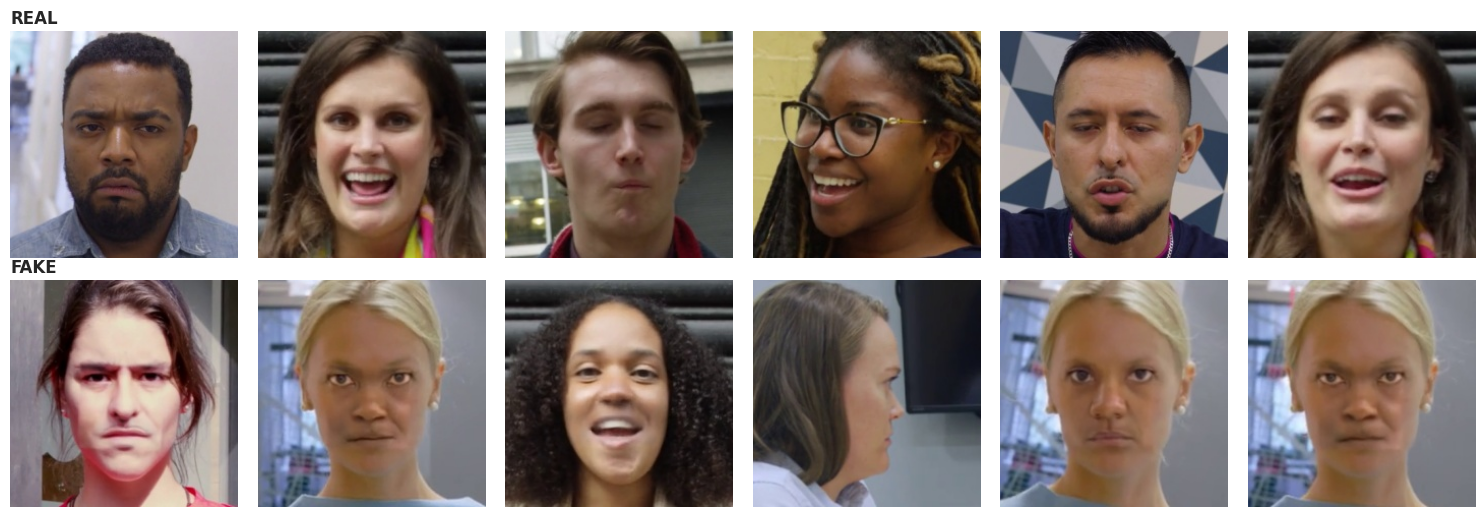

In [6]:
# Quick visual check: 6 real + 6 fake training crops
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for row, lab in enumerate([0, 1]):
    s = frame_df[(frame_df.split == "train") & (frame_df.label == lab)].sample(6, random_state=SEED)
    for ax, p in zip(axes[row], s.path):
        ax.imshow(Image.open(p)); ax.axis("off")
    axes[row][0].set_title("REAL" if lab == 0 else "FAKE", loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT_DIR / "sample_faces.png", dpi=120); plt.show()

## 3. Datasets, augmentation, dataloaders

In [7]:
train_tfm = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class FaceFrameDataset(Dataset):
    def __init__(self, frames, tfm):
        self.paths = frames["path"].tolist(); self.labels = frames["label"].astype("float32").tolist(); self.tfm = tfm
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tfm(img), torch.tensor(self.labels[i], dtype=torch.float32)

tr_f = frame_df[frame_df.split == "train"].reset_index(drop=True)
va_f = frame_df[frame_df.split == "val"].reset_index(drop=True)
te_f = frame_df[frame_df.split == "test"].reset_index(drop=True)

def worker_init(worker_id):
    s = SEED + worker_id; np.random.seed(s); random.seed(s)
g = torch.Generator(); g.manual_seed(SEED)

mk = lambda ds, shuffle: DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle,
                                    num_workers=CFG["num_workers"], pin_memory=use_amp,
                                    worker_init_fn=worker_init, generator=g if shuffle else None)
train_loader = mk(FaceFrameDataset(tr_f, train_tfm), True)
val_loader   = mk(FaceFrameDataset(va_f, eval_tfm), False)   # shuffle=False -> order matches va_f
test_loader  = mk(FaceFrameDataset(te_f, eval_tfm), False)   # shuffle=False -> order matches te_f
print(f"frames  train={len(tr_f)}  val={len(va_f)}  test={len(te_f)}")

frames  train=3360  val=720  test=720


## 4. Model and training (EfficientNet-B0, BCEWithLogitsLoss, AdamW, early stopping)

In [8]:
def build_model():
    try:
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    except Exception as e:
        raise RuntimeError("Could not load ImageNet weights. Turn Internet ON in Kaggle notebook settings.") from e
    in_f = m.classifier[1].in_features                 # 1280
    m.classifier[1] = nn.Linear(in_f, 1)               # single logit -> P(fake) after sigmoid
    return m

seed_everything()
model = build_model().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
print("Trainable params: %.2fM" % (sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 123MB/s] 


Trainable params: 4.01M


In [9]:
def run_epoch(loader, train):
    model.train(train)
    loss_sum, correct, total = 0.0, 0, 0
    for x, y in tqdm(loader, leave=False, desc="train" if train else "val"):
        x = x.to(device, non_blocking=True); y = y.to(device, non_blocking=True).unsqueeze(1)
        with torch.set_grad_enabled(train):
            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = model(x); loss = criterion(logits, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        loss_sum += loss.item() * x.size(0)
        correct += ((torch.sigmoid(logits) >= 0.5).float() == y).sum().item()
        total += x.size(0)
    return loss_sum / total, correct / total

history = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[])
best_val_loss, bad_epochs = float("inf"), 0
BEST_PATH = OUT_DIR / "efficientnet_b0_best.pt"

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, True)
    vl, va = run_epoch(val_loader, False)
    for k_, v_ in zip(history, (tl, vl, ta, va)): history[k_].append(v_)
    improved = vl < best_val_loss
    if improved:
        best_val_loss, bad_epochs = vl, 0
        torch.save(model.state_dict(), BEST_PATH)
    else:
        bad_epochs += 1
    print(f"Epoch {epoch}/{CFG['epochs']} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} "
          f"| {time.time()-t0:.0f}s {'<- best' if improved else ''}")
    if bad_epochs >= CFG["patience"]:
        print(f"Early stopping: no val-loss improvement for {CFG['patience']} epochs."); break

model.load_state_dict(torch.load(BEST_PATH, map_location=device))
model.eval()
pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)

train:   0%|          | 0/105 [00:00<?, ?it/s]

val:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch 1/5 | train loss 0.4858 acc 0.7762 | val loss 0.4175 acc 0.8319 | 30s <- best


train:   0%|          | 0/105 [00:00<?, ?it/s]

val:   0%|          | 0/23 [00:00<?, ?it/s]

...

val:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch 4/5 | train loss 0.1300 acc 0.9452 | val loss 0.4166 acc 0.8583 | 64s <- best


train:   0%|          | 0/105 [00:00<?, ?it/s]

val:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch 5/5 | train loss 0.1096 acc 0.9497 | val loss 0.5127 acc 0.8667 | 14s 


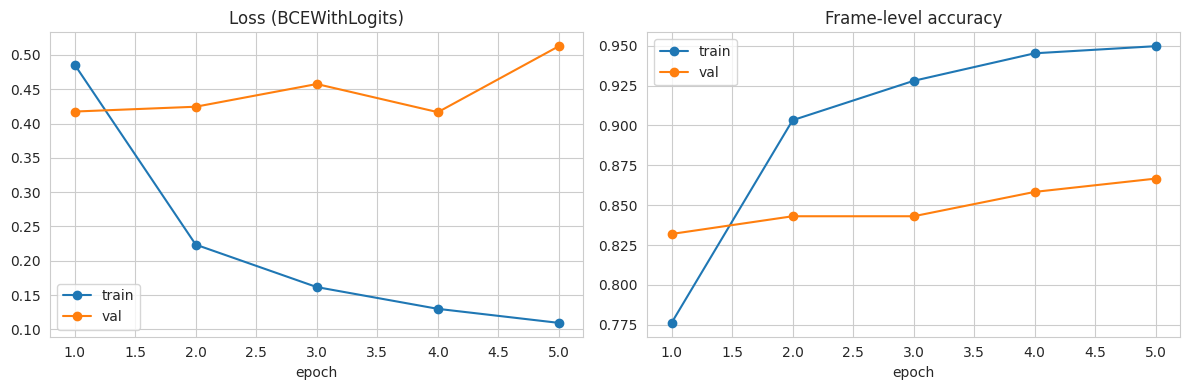

In [10]:
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history["train_loss"], "o-", label="train"); ax[0].plot(ep, history["val_loss"], "o-", label="val")
ax[0].set_title("Loss (BCEWithLogits)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, history["train_acc"], "o-", label="train"); ax[1].plot(ep, history["val_acc"], "o-", label="val")
ax[1].set_title("Frame-level accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=130); plt.show()

## 5. Video-level evaluation
Frame probabilities → **mean per video** → threshold chosen on the **validation** set (max F1) → applied unchanged to the test set.

In [21]:
@torch.no_grad()
def predict_frame_probs(loader):
    model.eval(); out = []
    for x, _ in tqdm(loader, leave=False, desc="infer"):
        with torch.amp.autocast("cuda", enabled=use_amp):
            out.append(torch.sigmoid(model(x.to(device, non_blocking=True))).float().cpu().numpy().ravel())
    return np.concatenate(out)

def aggregate_videos(frames, probs):
    d = frames[["video_id", "label"]].copy(); d["prob"] = probs
    v = d.groupby("video_id").agg(label=("label", "first"), score=("prob", "mean"),
                                  n_frames=("prob", "size")).reset_index()
    return v

def best_threshold(y, s):
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1s = np.array([f1_score(y, (s >= t).astype(int), zero_division=0) for t in grid])
    cands = grid[np.isclose(f1s, f1s.max())]
    return float(cands[np.argmin(np.abs(cands - 0.5))]), float(f1s.max()), grid, f1s   # ties -> closest to 0.5

def metrics_at(y, s, thr):
    pred = (s >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0),
                roc_auc=roc_auc_score(y, s) if len(np.unique(y)) > 1 else float("nan"))

val_probs, test_probs = predict_frame_probs(val_loader), predict_frame_probs(test_loader)
val_v, test_v = aggregate_videos(va_f, val_probs), aggregate_videos(te_f, test_probs)

# ---- Threshold: auto (validation F1) vs manual override ----
BEST_THR, val_best_f1, grid, f1s = best_threshold(val_v.label.values, val_v.score.values)
AUTO_THR = BEST_THR            # what validation F1 picked, kept for comparison
MANUAL_THR = 0.30              # set to None to use the auto value
if MANUAL_THR is not None:
    BEST_THR = MANUAL_THR
print(f"Auto (val-F1) threshold = {AUTO_THR:.2f} (val F1 = {val_best_f1:.4f}) | using threshold = {BEST_THR:.2f}")

val_m  = metrics_at(val_v.label.values,  val_v.score.values,  BEST_THR)
test_m = metrics_at(test_v.label.values, test_v.score.values, BEST_THR)
res = pd.DataFrame({"validation": val_m, "test": test_m}).T.round(4)
print("\nVIDEO-LEVEL METRICS"); display(res)
print(f"(val videos={len(val_v)}, test videos={len(test_v)} -> with so few test videos, treat metrics as indicative, not precise)")

# Optional: compare auto vs manual threshold side by side (test metrics shown for information only)
cmp = pd.DataFrame({
    f"val @ auto {AUTO_THR:.2f}":   metrics_at(val_v.label.values,  val_v.score.values,  AUTO_THR),
    f"val @ used {BEST_THR:.2f}":   val_m,
    f"test @ auto {AUTO_THR:.2f}":  metrics_at(test_v.label.values, test_v.score.values, AUTO_THR),
    f"test @ used {BEST_THR:.2f}":  test_m,
}).T.round(4)
print("\nTHRESHOLD COMPARISON"); display(cmp)

val_v.to_csv(OUT_DIR / "val_video_predictions.csv", index=False)
test_v.to_csv(OUT_DIR / "test_video_predictions.csv", index=False)
res.to_csv(OUT_DIR / "video_level_metrics.csv")
json.dump({"threshold": BEST_THR, "auto_threshold": AUTO_THR, "validation": val_m, "test": test_m},
          open(OUT_DIR / "metrics.json", "w"), indent=2)

infer:   0%|          | 0/23 [00:00<?, ?it/s]

infer:   0%|          | 0/23 [00:00<?, ?it/s]

Auto (val-F1) threshold = 0.70 (val F1 = 0.9180) | using threshold = 0.30

VIDEO-LEVEL METRICS


,accuracy,precision,recall,f1,roc_auc
validation,0.8500,0.7692,1.0000,0.8696,0.9600
test,0.8833,0.8485,0.9333,0.8889,0.9556


(val videos=60, test videos=60 -> with so few test videos, treat metrics as indicative, not precise)

THRESHOLD COMPARISON


,accuracy,precision,recall,f1,roc_auc
val @ auto 0.70,0.9167,0.9032,0.9333,0.9180,0.9600
val @ used 0.30,0.8500,0.7692,1.0000,0.8696,0.9600
test @ auto 0.70,0.8500,0.9565,0.7333,0.8302,0.9556
test @ used 0.30,0.8833,0.8485,0.9333,0.8889,0.9556


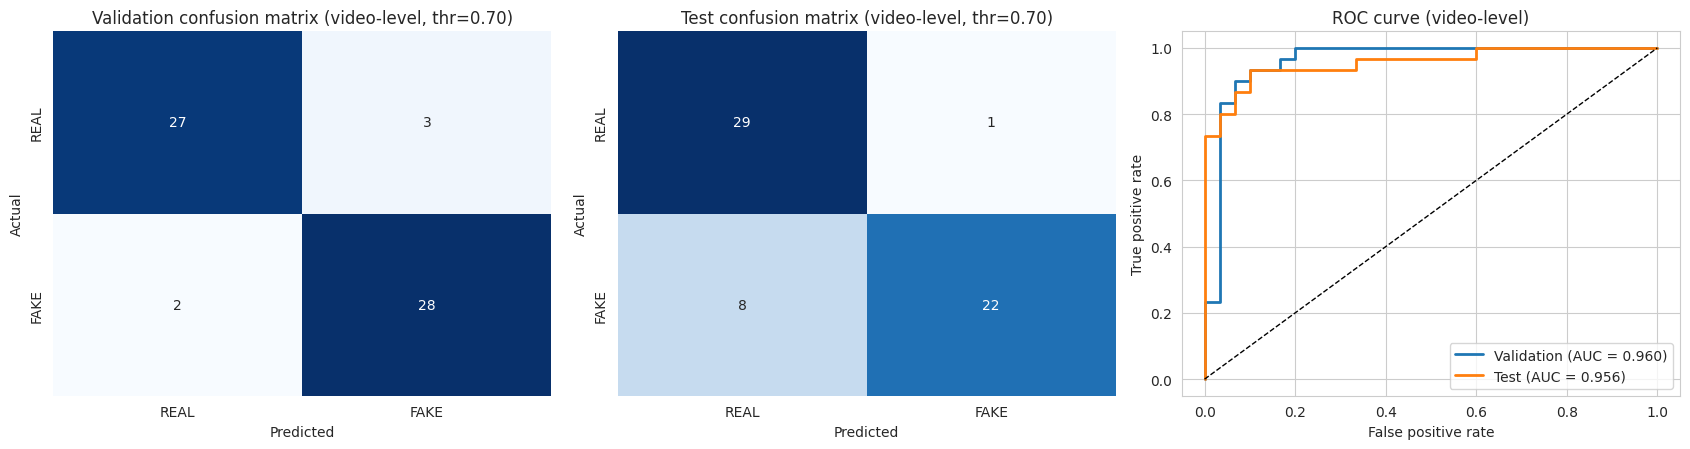

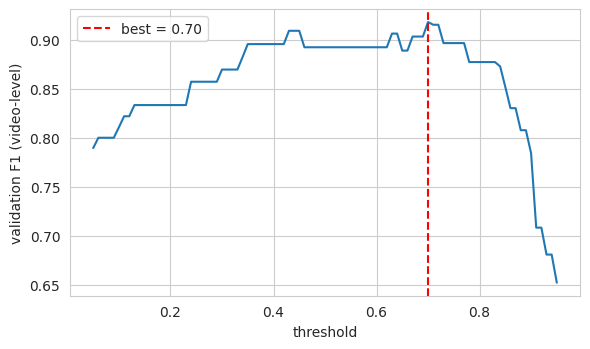

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, v, title in [(ax[0], val_v, "Validation"), (ax[1], test_v, "Test")]:
    cm = confusion_matrix(v.label, (v.score >= BEST_THR).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["REAL", "FAKE"], yticklabels=["REAL", "FAKE"])
    a.set_title(f"{title} confusion matrix (video-level, thr={BEST_THR:.2f})"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
for v, name in [(val_v, "Validation"), (test_v, "Test")]:
    fpr, tpr, _ = roc_curve(v.label, v.score)
    ax[2].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(v.label, v.score):.3f})")
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].set_title("ROC curve (video-level)"); ax[2].legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_roc.png", dpi=130); plt.show()

# separate files for the report
for v, name in [(val_v, "val"), (test_v, "test")]:
    cm = confusion_matrix(v.label, (v.score >= BEST_THR).astype(int), labels=[0, 1])
    plt.figure(figsize=(4.2, 3.6)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["REAL", "FAKE"], yticklabels=["REAL", "FAKE"]); plt.title(f"Confusion matrix ({name})")
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.tight_layout(); plt.savefig(OUT_DIR / f"confusion_matrix_{name}.png", dpi=130); plt.close()
fpr, tpr, _ = roc_curve(test_v.label, test_v.score)
plt.figure(figsize=(4.8, 4.2)); plt.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(test_v.label, test_v.score):.3f}")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC curve (test, video-level)")
plt.legend(); plt.tight_layout(); plt.savefig(OUT_DIR / "roc_curve_test.png", dpi=130); plt.close()

# validation F1 vs threshold
plt.figure(figsize=(6, 3.6)); plt.plot(grid, f1s); plt.axvline(BEST_THR, color="r", ls="--", label=f"best = {BEST_THR:.2f}")
plt.xlabel("threshold"); plt.ylabel("validation F1 (video-level)"); plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR / "threshold_vs_f1.png", dpi=130); plt.show()

## 6. Save artifacts and single-video inference (this is what the TruthLens backend will call)

In [13]:
FINAL_PATH = OUT_DIR / "truthlens_video_efficientnet_b0.pt"
torch.save({"arch": "efficientnet_b0", "state_dict": model.state_dict(), "threshold": BEST_THR,
            "img_size": CFG["img_size"], "frames_per_video": CFG["frames_per_video"],
            "face_margin": CFG["face_margin"], "mean": IMAGENET_MEAN, "std": IMAGENET_STD,
            "label_map": {0: "REAL", 1: "FAKE"}}, FINAL_PATH)
json.dump({"threshold": BEST_THR, "frames_per_video": CFG["frames_per_video"], "img_size": CFG["img_size"]},
          open(OUT_DIR / "best_threshold.json", "w"), indent=2)
print("Saved:", FINAL_PATH, f"({FINAL_PATH.stat().st_size/1e6:.1f} MB)")

Saved: /kaggle/working/outputs/truthlens_video_efficientnet_b0.pt (16.3 MB)


In [14]:
def decision_confidence(score, thr):
    # Heuristic confidence in [0.5, 1]: how far the score is from the decision threshold, rescaled per side.
    # NOT a calibrated probability.
    if score >= thr:
        return 0.5 + 0.5 * (score - thr) / max(1e-9, 1 - thr)
    return 0.5 + 0.5 * (thr - score) / max(1e-9, thr)

@torch.no_grad()
def predict_video(video_path, threshold=None, mdl=None):
    # Full pipeline for ONE video. Returns a JSON-serialisable dict for the TruthLens report.
    mdl = mdl or model; threshold = BEST_THR if threshold is None else threshold
    t0 = time.time()
    faces, n_read, n_det = extract_faces(video_path)
    if len(faces) == 0:
        return {"status": "error", "message": "Could not read any frames from this video."}
    x = torch.stack([eval_tfm(Image.fromarray(f)) for f in faces]).to(device)
    mdl.eval()
    with torch.amp.autocast("cuda", enabled=use_amp):
        probs = torch.sigmoid(mdl(x)).float().cpu().numpy().ravel()
    score = float(probs.mean())
    label = "FAKE" if score >= threshold else "REAL"
    return {
        "status": "ok",
        "video": Path(video_path).name,
        "prediction": label,
        "confidence": round(float(decision_confidence(score, threshold)), 4),
        "fake_score": round(score, 4),                     # mean frame P(fake)
        "threshold": threshold,
        "frames_analyzed": int(len(probs)),
        "frames_with_face": int(n_det),
        "face_fallback_used": bool(n_det == 0),
        "frame_probabilities": [round(float(p), 4) for p in probs],
        "model": "EfficientNet-B0 (FaceForensics++ subset)",
        "processing_seconds": round(time.time() - t0, 2),
    }

# Demo on two held-out test videos (one real, one fake)
demo = pd.concat([test_df[test_df.label == 0].head(1), test_df[test_df.label == 1].head(1)])
for r in demo.itertuples():
    out = predict_video(r.path)
    print("Ground truth:", "FAKE" if r.label else "REAL")
    print(json.dumps({k: v for k, v in out.items() if k != "frame_probabilities"}, indent=2), "\n")

Ground truth: REAL
{
  "status": "ok",
  "video": "15__walking_outside_cafe_disgusted.mp4",
  "prediction": "REAL",
  "confidence": 0.9988,
  "fake_score": 0.0016,
  "threshold": 0.7,
  "frames_analyzed": 12,
  "frames_with_face": 12,
  "face_fallback_used": false,
  "model": "EfficientNet-B0 (FaceForensics++ subset)",
  "processing_seconds": 8.98
} 

Ground truth: FAKE
{
  "status": "ok",
  "video": "09_02__walking_down_street_outside_angry__6KUOFMZW.mp4",
  "prediction": "FAKE",
  "confidence": 0.9974,
  "fake_score": 0.9985,
  "threshold": 0.7,
  "frames_analyzed": 12,
  "frames_with_face": 12,
  "face_fallback_used": false,
  "model": "EfficientNet-B0 (FaceForensics++ subset)",
  "processing_seconds": 5.2
} 



In [15]:
# Reload-from-disk check: proves the saved checkpoint works standalone (what the backend will do)
ckpt = torch.load(FINAL_PATH, map_location=device)
m2 = models.efficientnet_b0(weights=None); m2.classifier[1] = nn.Linear(m2.classifier[1].in_features, 1)
m2.load_state_dict(ckpt["state_dict"]); m2 = m2.to(device).eval()
r = test_df.iloc[0]
print("reloaded model ->", predict_video(r.path, threshold=ckpt["threshold"], mdl=m2)["prediction"],
      "| ground truth:", "FAKE" if r.label else "REAL")

reloaded model -> REAL | ground truth: REAL


## 7. Hooking this into TruthLens

Your backend is Node.js, so serve the model as a small Python service and call it from Node:

```
React upload → Node (multer saves file) → POST /analyze-video → Python service → predict_video() → JSON → Node stores in MongoDB → report page
```

- Download from `/kaggle/working/outputs/`: `truthlens_video_efficientnet_b0.pt` (weights + threshold + preprocessing settings).
- In the service, copy `extract_faces()` and its helpers (sample/detect/align/crop) from section 2 — **inference must use the exact same preprocessing as training**.
- The dict returned by `predict_video()` maps directly onto the report: `prediction`, `confidence`, `fake_score`, `frames_analyzed`, `frame_probabilities` (per-frame chart).

## Caveats worth stating in your report
- **Source-identity leakage:** FF++ fakes are made from the real videos, so a random video-level split can put a real video in train and its manipulated twin in test. Metrics may be optimistic; a split grouped by source id would be stricter.
- **Small test set:** 15% of 400 = ~60 videos, so one video moves accuracy by ~1.7%.
- **Cross-dataset generalisation is not tested here** (e.g. Celeb-DF, DFDC); expect lower accuracy on unseen manipulation methods and compression levels.
- `confidence` is a threshold-relative score, not a calibrated probability.

In [17]:
import ipywidgets as widgets
from IPython.display import display, clear_output

UPLOAD_DIR = Path("/kaggle/working/uploads")
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)
UPLOADED_VIDEO = None

uploader = widgets.FileUpload(accept=".mp4,.avi,.mov,.mkv,.webm", multiple=False,
                              description="Upload video")
status = widgets.Output()

def on_upload(change):
    global UPLOADED_VIDEO
    v = uploader.value
    items = list(v.values()) if isinstance(v, dict) else list(v)   # ipywidgets v7 vs v8
    if not items:
        return
    item = items[0]
    path = UPLOAD_DIR / item["name"]
    path.write_bytes(bytes(item["content"]))
    UPLOADED_VIDEO = str(path)
    with status:
        clear_output()
        print(f"Uploaded: {path.name} ({path.stat().st_size / 1e6:.1f} MB)")
        print("Now run the Analyse cell.")

uploader.observe(on_upload, names="value")
display(uploader, status)

# If the widget doesn't render on your Kaggle session, use one of these instead:
#   1) Upload via the right panel (Input -> Upload) and set the path manually:
#      UPLOADED_VIDEO = "/kaggle/working/my_video.mp4"
#   2) Quick test with a held-out video from the dataset:
#      UPLOADED_VIDEO = str(test_df.iloc[0].path)

FileUpload(value=(), accept='.mp4,.avi,.mov,.mkv,.webm', description='Upload video')

Output()

 TRUTHLENS VIDEO ANALYSIS REPORT
 Video            : YouTube Shorts 3 Minute limit update.mp4
 Prediction       : REAL
 Confidence       : 99.3%
 Mean fake score  : 0.0044  (threshold 0.30)
 Frames analysed  : 12  (faces found in 12)
 Processing time  : 1.76s


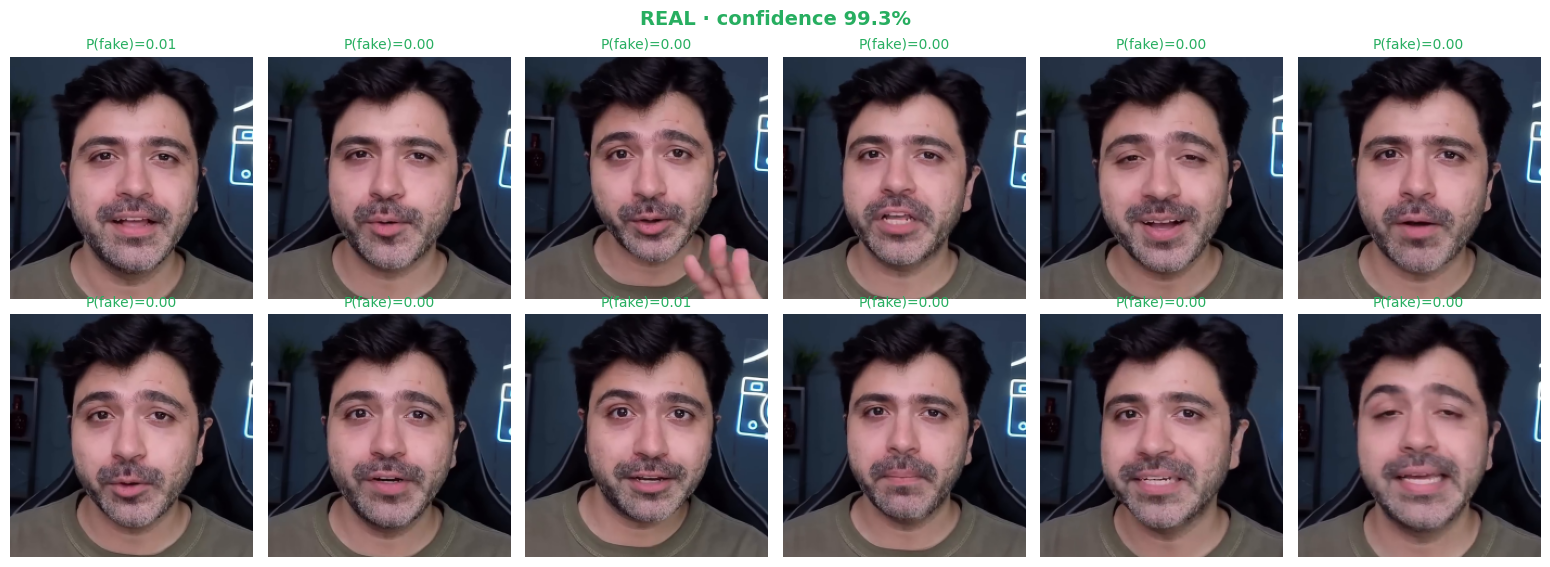

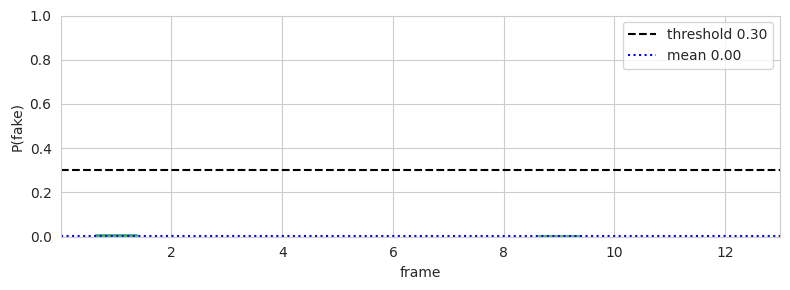

{
  "status": "ok",
  "video": "YouTube Shorts 3 Minute limit update.mp4",
  "prediction": "REAL",
  "confidence": 0.9927,
  "fake_score": 0.0044,
  "threshold": 0.3,
  "frames_analyzed": 12,
  "frames_with_face": 12,
  "face_fallback_used": false,
  "model": "EfficientNet-B0 (FaceForensics++ subset)",
  "processing_seconds": 1.76
}


In [26]:
# Pick the video: uploaded one, otherwise fall back to a held-out test video so you can still verify the pipeline
video_path = globals().get("UPLOADED_VIDEO")
truth = None
if not video_path:
    row = test_df.iloc[0]
    video_path, truth = row.path, ("FAKE" if row.label == 1 else "REAL")
    print("No upload found -> using a held-out test video:", Path(video_path).name)

result = predict_video(video_path)
assert result["status"] == "ok", result

# ---- Report ----
colour = "#c0392b" if result["prediction"] == "FAKE" else "#27ae60"
print("=" * 52)
print(f" TRUTHLENS VIDEO ANALYSIS REPORT")
print("=" * 52)
print(f" Video            : {result['video']}")
print(f" Prediction       : {result['prediction']}")
print(f" Confidence       : {result['confidence'] * 100:.1f}%")
print(f" Mean fake score  : {result['fake_score']:.4f}  (threshold {result['threshold']:.2f})")
print(f" Frames analysed  : {result['frames_analyzed']}  (faces found in {result['frames_with_face']})")
print(f" Processing time  : {result['processing_seconds']}s")
if result["face_fallback_used"]:
    print(" [!] No face detected - center-crop fallback used, treat result as unreliable")
if truth:
    print(f" Ground truth     : {truth}  ->  {'CORRECT' if truth == result['prediction'] else 'WRONG'}")
print("=" * 52)

# ---- Per-frame view (same extraction as inference, so order matches the probabilities) ----
faces, _, _ = extract_faces(video_path)
probs = result["frame_probabilities"]
cols = 6
rows = math.ceil(len(faces) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.9 * rows))
axes = np.atleast_1d(axes).ravel()
for ax, f, p in zip(axes, faces, probs):
    ax.imshow(f); ax.axis("off")
    is_fake = p >= result["threshold"]
    ax.set_title(f"P(fake)={p:.2f}", color="#c0392b" if is_fake else "#27ae60", fontsize=10)
for ax in axes[len(faces):]:
    ax.axis("off")
fig.suptitle(f"{result['prediction']} · confidence {result['confidence'] * 100:.1f}%",
             color=colour, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

# ---- Frame probability chart ----
plt.figure(figsize=(8, 3))
plt.bar(range(1, len(probs) + 1), probs, color=["#c0392b" if p >= result["threshold"] else "#27ae60" for p in probs])
plt.axhline(result["threshold"], color="k", ls="--", label=f"threshold {result['threshold']:.2f}")
plt.axhline(result["fake_score"], color="b", ls=":", label=f"mean {result['fake_score']:.2f}")
plt.ylim(0, 1); plt.xlabel("frame"); plt.ylabel("P(fake)"); plt.legend(); plt.tight_layout(); plt.show()

# JSON the backend would receive
print(json.dumps({k: v for k, v in result.items() if k != "frame_probabilities"}, indent=2))